# NewsMood — 02. Évaluation des modèles de sentiment

**Objectif :** mesurer avec des chiffres quel modèle est le meilleur, TextBlob ou FinBERT.

**Deux jeux de données annotés à la main :**
- **Financial PhraseBank** (2 264 phrases, annotateurs unanimes) — ⚠️ FinBERT a été entraîné dessus : risque de *fuite de données* (score gonflé).
- **Twitter Financial News** (partie validation) — jamais vu par FinBERT : c'est le vrai test.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import pandas as pd
from datasets import load_dataset

# --- 1. Financial PhraseBank -----------------------------------------------
# Copie publiee par le FinTech Lab de Georgia Tech (benchmark FLaME).
# Elle est coupee en "train" (environ 1 580 phrases) et "test" (environ 680 phrases) :
# on recolle les deux pour retrouver les 2 264 phrases.
fpb_parts = load_dataset("gtfintechlab/financial_phrasebank_sentences_allagree", "5768")
fpb = pd.concat([fpb_parts["train"].to_pandas(), fpb_parts["test"].to_pandas()], ignore_index=True)
fpb = fpb.rename(columns={"sentence": "text"})[["text", "label"]]
fpb["label"] = fpb["label"].map({0: "negative", 1: "neutral", 2: "positive"})

# --- 2. Twitter Financial News (partie validation) ------------------------
tw = load_dataset("zeroshot/twitter-financial-news-sentiment")["validation"].to_pandas()
tw["label"] = tw["label"].map({0: "negative", 1: "positive", 2: "neutral"})  # Bearish / Bullish / Neutral

# --- On regarde ------------------------------------------------------------
for nom, df in [("Financial PhraseBank", fpb), ("Twitter Financial News", tw)]:
    print(f"=== {nom} : {len(df)} textes ===")
    print((df["label"].value_counts(normalize=True) * 100).round(1).to_string())
    print()

print("Exemples PhraseBank :")
print(fpb.sample(3, random_state=42).to_string(index=False))
print("\nExemples Twitter :")
print(tw.sample(3, random_state=42).to_string(index=False))

c:\Users\Dell\projets\newsmood\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


=== Financial PhraseBank : 2264 textes ===
label
neutral     61.4
positive    25.2
negative    13.4

=== Twitter Financial News : 2388 textes ===
label
neutral     65.6
positive    19.9
negative    14.5

Exemples PhraseBank :
                                                                                    text    label
The acquisition will have an immediate positive impact on Aspocomp 's financial result . positive
                             Sales of security and system packaging increased slightly . positive
                    - Counter your competitor 's strengths and target their weaknesses .  neutral

Exemples Twitter :
                                                                                                                                        text   label
Two key regulators are holding off on easing Wall Street debt limits, leaving billions of dollars locked up that co… https://t.co/YvDDlEcmh2 neutral
            Xinjiang Xinxin Mining Industry : ANNOUNCEMENT - RES

## 1. Scores des modèles

Métrique principale : **F1-score macro** (les classes sont déséquilibrées : 61 à 66 % de neutres).
Référence (*baseline*) : un modèle qui répond toujours « neutral ».

In [2]:
import time
from sklearn.metrics import accuracy_score, f1_score
from src.sentiment import textblob_predict, finbert_predict

LABELS = ["negative", "neutral", "positive"]

def evaluer(df, nom_jeu):
    """Fait predire les 3 modeles sur df, ajoute les predictions a df, renvoie un tableau de scores."""
    textes = df["text"].tolist()
    y_true = df["label"].tolist()
    lignes = []

    modeles = {
        "Toujours neutre": lambda t: [{"label": "neutral"}] * len(t),
        "TextBlob": textblob_predict,
        "FinBERT": finbert_predict,
    }
    for nom_modele, predire in modeles.items():
        debut = time.time()
        y_pred = [r["label"] for r in predire(textes)]
        duree = time.time() - debut

        df[f"pred_{nom_modele}"] = y_pred   # on garde les predictions pour l'analyse des erreurs
        lignes.append({
            "jeu": nom_jeu,
            "modele": nom_modele,
            "accuracy": round(accuracy_score(y_true, y_pred), 3),
            "f1_macro": round(f1_score(y_true, y_pred, labels=LABELS, average="macro"), 3),
            "temps_s": round(duree, 1),
        })
        print(f"{nom_jeu} - {nom_modele} : termine en {duree:.0f} s")
    return pd.DataFrame(lignes)

scores = pd.concat([evaluer(fpb, "PhraseBank"), evaluer(tw, "Twitter")], ignore_index=True)
scores

PhraseBank - Toujours neutre : termine en 0 s
PhraseBank - TextBlob : termine en 1 s


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 220.80it/s]


PhraseBank - FinBERT : termine en 209 s
Twitter - Toujours neutre : termine en 0 s
Twitter - TextBlob : termine en 3 s
Twitter - FinBERT : termine en 177 s


,jeu,modele,accuracy,f1_macro,temps_s
0,PhraseBank,Toujours neutre,0.614,0.254,0.0
1,PhraseBank,TextBlob,0.543,0.467,0.5
2,PhraseBank,FinBERT,0.972,0.963,209.1
3,Twitter,Toujours neutre,0.656,0.264,0.0
4,Twitter,TextBlob,0.503,0.385,2.7
5,Twitter,FinBERT,0.725,0.668,177.3


## 2. Où les modèles se trompent-ils ? (Twitter, jeu jamais vu par FinBERT)

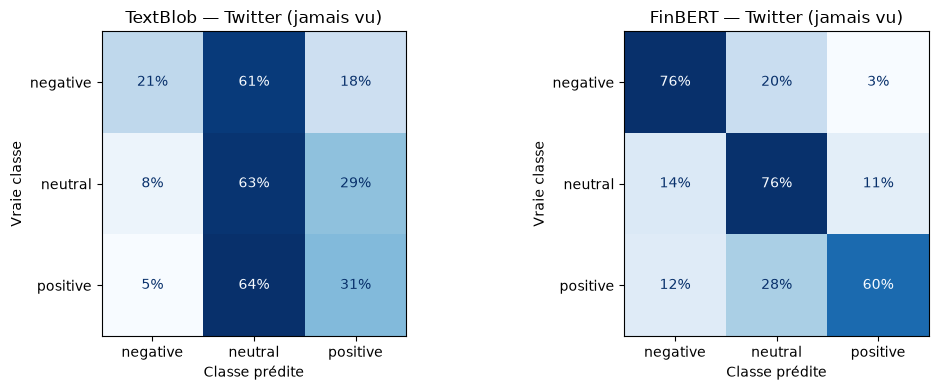

              precision    recall  f1-score   support

    negative      0.493     0.761     0.599       347
     neutral      0.853     0.756     0.802      1566
    positive      0.611     0.598     0.604       475

    accuracy                          0.725      2388
   macro avg      0.652     0.705     0.668      2388
weighted avg      0.753     0.725     0.733      2388



In [3]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, modele in zip(axes, ["TextBlob", "FinBERT"]):
    # normalize="true" : chaque ligne = 100 % des textes de cette vraie classe
    ConfusionMatrixDisplay.from_predictions(
        tw["label"], tw[f"pred_{modele}"], labels=LABELS,
        normalize="true", values_format=".0%", cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(f"{modele} — Twitter (jamais vu)")
    ax.set_xlabel("Classe prédite")
    ax.set_ylabel("Vraie classe")
plt.tight_layout()
plt.show()

# Precision, rappel et F1 pour chaque classe (FinBERT)
print(classification_report(tw["label"], tw["pred_FinBERT"], labels=LABELS, digits=3))

In [4]:
pd.set_option("display.max_colwidth", 130)   # afficher les textes en entier

erreurs = tw[tw["label"] != tw["pred_FinBERT"]]
print("Nombre d'erreurs de FinBERT :", len(erreurs), "sur", len(tw))
erreurs.sample(12, random_state=42)[["text", "label", "pred_FinBERT"]]

Nombre d'erreurs de FinBERT : 656 sur 2388


,text,label,pred_FinBERT
787,Oil pared losses amid signs that Saudi Arabia and Russia are making progress toward an agreement to curb crude outp… https://t...,positive,negative
1042,"Activism Rises In Japan as Firms Go Hostile, Investors Speak Out",neutral,negative
323,CAE : completes upgrades of CT-156 and CT-155 FTDs for NFTC program at 15 Wing Moose Jaw #CAE #Stock… https://t.co/QtvyZaPnzE,neutral,positive
2287,"Tyson Foods -4% after chicken, beef sales disappoint",negative,neutral
1948,"$CERN - Cerner: Undervalued, Wide Moat, Dominant. Read more: https://t.co/4KImEZVaU1 #finance #markets #economy",positive,neutral
442,Semafo to restart mining at its Boungou in Q4; provides 2020 outlook,neutral,positive
925,"Molina Healthcare EPS beats by $0.07, misses on revenue",neutral,positive
1005,$SPX There are still ZERO confirmed cases of novel #coronavirus in NYC.,neutral,negative
232,Pershing Square Holdings announces new $100M share buyback program,positive,neutral
882,"Construction Partners EPS in-line, beats on revenue",positive,neutral


## 3. Conclusions de l'évaluation

| Jeu de données | Toujours neutre | TextBlob | FinBERT |
| --- | --- | --- | --- |
| Financial PhraseBank (vu par FinBERT) | 0,254 | 0,467 | 0,963 |
| **Twitter Financial News (jamais vu)** | **0,264** | **0,385** | **0,668** |

*F1-score macro. Le temps de calcul de FinBERT est d'environ 3 minutes pour 2 400 textes sur CPU.*

1. **FinBERT est nettement le meilleur modèle** sur des données jamais vues (F1 macro de 0,67 contre 0,39 pour TextBlob). C'est le modèle retenu pour le projet.
2. **TextBlob ne comprend pas le vocabulaire financier** : il répond « neutral » dans environ 63 % des cas, quelle que soit la vraie classe. Son accuracy (0,54) est même inférieure à celle de la baseline.
3. **Fuite de données :** FinBERT a été entraîné sur Financial PhraseBank. Son score de 0,96 sur ce jeu est gonflé. L'écart avec Twitter (−30 points) mélange cet effet et le changement de style (tweets contre phrases de presse).
4. **Défauts de FinBERT :** il surestime le négatif (précision de 0,49 sur cette classe) et rate 28 % des textes positifs. En Phase 4, on analysera donc surtout les **variations** du sentiment, plutôt que son niveau absolu.
5. **Limites :** environ la moitié des erreurs examinées sont des cas ambigus (nouvelles mitigées, désaccord possible entre humains). Et FinBERT donne un seul sentiment par texte, sans savoir à quelle entreprise il s'applique.